# Support Vector Machines 
## Exercise

## [Fraud in Wine](https://en.wikipedia.org/wiki/Wine_fraud)

Wine fraud relates to the commercial aspects of wine. The most prevalent type of fraud is one where wines are adulterated, usually with the addition of cheaper products (e.g. juices) and sometimes with harmful chemicals and sweeteners (compensating for color or flavor).

Counterfeiting and the relabelling of inferior and cheaper wines to more expensive brands is another common type of wine fraud.

<img src="wine.jpg">

## Project Goals

A distribution company that was recently a victim of fraud has completed an audit of various samples of wine through the use of chemical analysis on samples. The distribution company specializes in exporting extremely high quality, expensive wines, but was defrauded by a supplier who was attempting to pass off cheap, low quality wine as higher grade wine. The distribution company has hired you to attempt to create a machine learning model that can help detect low quality (a.k.a "fraud") wine samples. They want to know if it is even possible to detect such a difference.

Data Source: *P. Cortez, A. Cerdeira, F. Almeida, T. Matos and J. Reis. Modeling wine preferences by data mining from physicochemical properties. In Decision Support Systems, Elsevier, 47(4):547-553, 2009.*

---
---

**TASK: Your overall goal is to use the wine dataset shown below to develop a machine learning model that attempts to predict if a wine is "Legit" or "Fraud" based on various chemical features. Complete the tasks below to follow along with the project.**

---
---


## Complete the Tasks in bold

**TASK: Run the cells below to import the libraries and load the dataset.**

In [102]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [103]:
df = pd.read_csv(r"C:\Users\fafzali\Downloads\Machine learning\Code\Week#7\wine_fraud.csv")

In [104]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,Legit,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,Legit,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,Legit,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,Legit,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,Legit,red


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   object 
 12  type                  6497 non-null   object 
dtypes: float64(11), object(2)
memory usage: 660.0+ KB


In [21]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality', 'type'],
      dtype='object')

C:\Users\fafzali\AppData\Local\Temp\ipykernel_33736\2149272493.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x=df['fixed acidity'],bins=4,kde=False)


<Axes: >

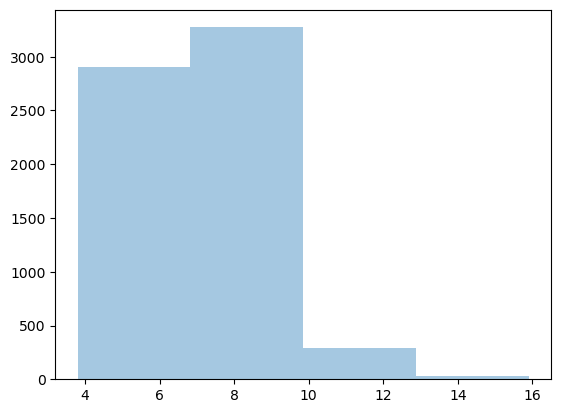

In [26]:
sns.distplot(x=df['fixed acidity'],bins=4,kde=False)

<Axes: xlabel='volatile acidity', ylabel='quality'>

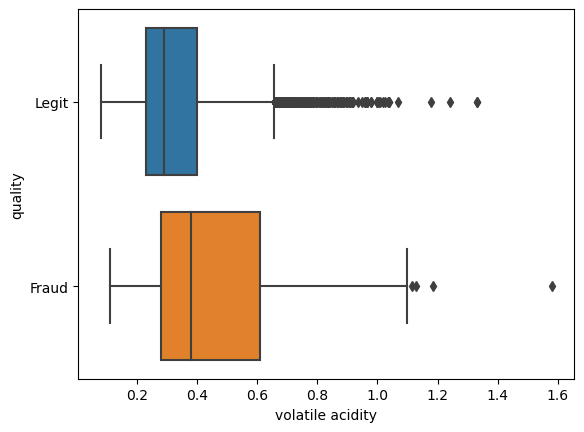

In [30]:
sns.boxplot(data=df,x='volatile acidity',y='quality')

**TASK: Identify and list the distinct values present in the target column we aim to predict, which is the 'quality' of the wine.**


In [16]:
df['quality'].value_counts()

Legit    6251
Fraud     246
Name: quality, dtype: int64

array(['Legit', 'Fraud'], dtype=object)

**TASK: Generate a countplot illustrating the distribution of samples in the 'Legit' and 'Fraud' categories. Evaluate whether the labels/target exhibit a balanced or unbalanced distribution.**


In [ ]:
# CODE HERE

<Axes: xlabel='quality', ylabel='count'>

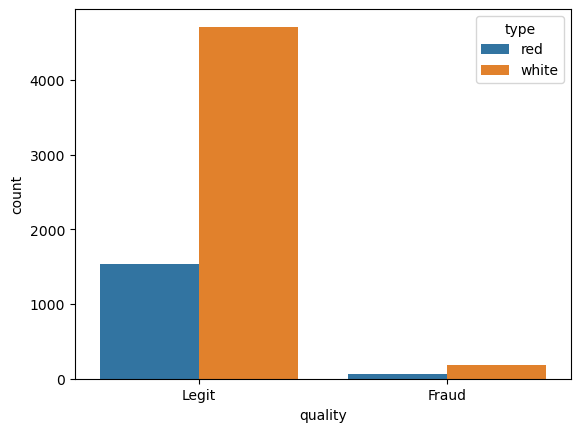

In [17]:
sns.countplot(data=df, x='quality', hue='type')

**TASK: Investigate whether there is a distinction between red and white wine regarding fraud cases. Create a countplot with 'wine type' on the x-axis and a color hue distinguishing between 'Fraud' and 'Legit' categories.**


In [ ]:
# CODE HERE

<Axes: xlabel='type', ylabel='count'>

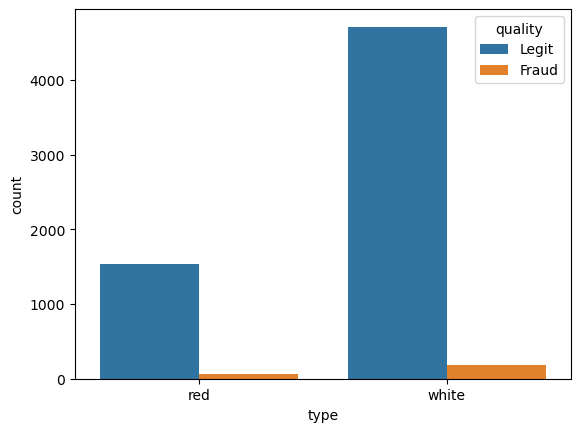

In [18]:
sns.countplot(data=df,x='type',hue='quality')

<AxesSubplot:xlabel='type', ylabel='count'>

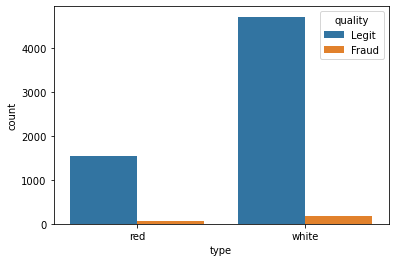

In [101]:
sns.counterplot()

**TASK: Calculate the percentage of fraudulent cases among red wines and the percentage of fraudulent cases among white wines.**


In [87]:

p={}   
for j in df['type'].unique():
    
    p[j]=len(df[(df['quality']=='Fraud') & (df['type']==j)])/len(df[(df['quality']=='Fraud')])

             


In [88]:
p

{'red': 0.25609756097560976, 'white': 0.7439024390243902}

In [60]:
for j in df['type'].unique():
    print(j)

red
white


Percentage of fraud in White Wines:
3.7362188648427925


**TASK: Compute the correlation between the different features and the "quality" column. You might need to convert the "quality" column to numeric values (0 and 1) from its string representation.**


In [ ]:
# CODE HERE

In [98]:
df=pd.get_dummies(data=df,columns=['quality'])

In [101]:
df.drop(['quality_Fraud','quality_Legit'],axis=1)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,red
1,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,red
2,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,red
3,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,red
4,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,red
...,...,...,...,...,...,...,...,...,...,...,...,...
9456,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,white
9457,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,white
9458,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,white
9459,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,white


fixed acidity           0.021794
volatile acidity        0.151228
citric acid            -0.061789
residual sugar         -0.048756
chlorides               0.034499
free sulfur dioxide    -0.085204
total sulfur dioxide   -0.035252
density                 0.016351
pH                      0.020107
sulphates              -0.034046
alcohol                -0.051141
Fraud                   1.000000
Name: Fraud, dtype: float64

**TASK: Create a bar plot of the correlation values to Fraudlent wine.**

In [ ]:
# CODE HERE

<AxesSubplot:>

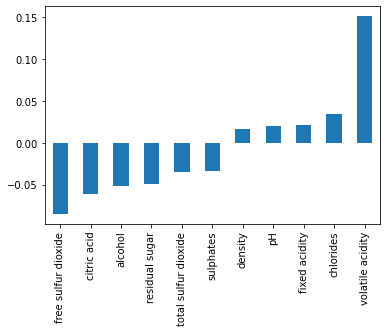

**TASK: Utilize Seaborn to construct a clustermap that visualizes the interrelationships among variables.**


In [ ]:
# CODE HERE

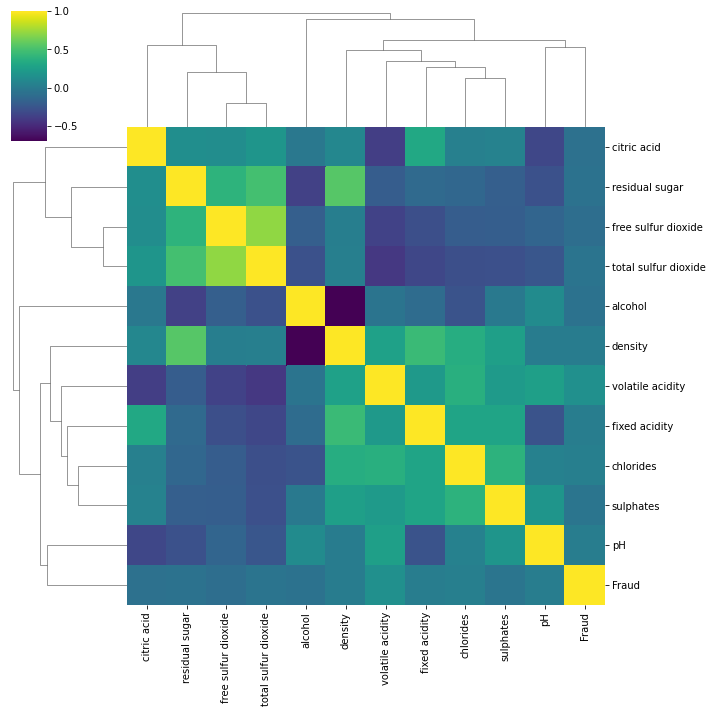

----
## Machine Learning Model

**TASK: Convert the categorical column "type" from a string or "red" or "white" to dummy variables:**

In [ ]:
# CODE HERE

**TASK: Separate out the data into X features and y target label ("quality" column)**

**TASK: Perform a Train|Test split on the data, with a 10% test size. Note: The solution uses a random state of 101**

**TASK: Scale the X train and X test data.**

**TASK: Create an instance of a Support Vector Machine classifier. Previously we have left this model "blank", (e.g. with no parameters). However, we already know that the classes are unbalanced, in an attempt to help alleviate this issue, we can automatically adjust weights inversely proportional to class frequencies in the input data with a argument call in the SVC() call. Check out the [documentation for SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html) online and look up what the argument\parameter is.**

In [135]:
# CODE HERE

**TASK: Use a GridSearchCV to run a grid search for the best C and gamma parameters.**

In [139]:
# CODE HERE

GridSearchCV(estimator=SVC(class_weight='balanced'),
             param_grid={'C': [0.001, 0.01, 0.1, 0.5, 1],
                         'gamma': ['scale', 'auto']})

{'C': 1, 'gamma': 'auto'}

**TASK: Display the confusion matrix and classification report for your model.**

array([[ 17,  10],
       [ 92, 531]], dtype=int64)

              precision    recall  f1-score   support

       Fraud       0.16      0.63      0.25        27
       Legit       0.98      0.85      0.91       623

    accuracy                           0.84       650
   macro avg       0.57      0.74      0.58       650
weighted avg       0.95      0.84      0.88       650



**TASK: Finally, think about how well this model performed, would you suggest using it? Realistically will this work?**

In [ ]:
# ANSWER: View the solutions video for full discussion on this.